/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Mounted at /content/drive
Loading initial structure...
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Initializing velocities for 300 K...

Running NVE simulation for 10000 steps (10.0 ps)...


/tmp/ipykernel_2837/703324265.py:32: DeprecationWarning: Use thermalize_momenta
  MaxwellBoltzmannDistribution(atoms, temperature_K=300.0)
/usr/local/lib/python3.13/dist-packages/ase/atoms.py:1123: UserWarning: Periodic boundary conditions are ignored when calculating the inertial tensor.
  warnings.warn('Periodic boundary conditions are ignored '


Step     0 | Time    0.0 fs | E_pot: -479.343 eV | E_kin: 3.571 eV | E_tot: -475.77199 eV
Step   500 | Time  500.0 fs | E_pot: -479.513 eV | E_kin: 3.777 eV | E_tot: -475.73616 eV
Step  1000 | Time 1000.0 fs | E_pot: -479.455 eV | E_kin: 3.719 eV | E_tot: -475.73573 eV
Step  1500 | Time 1500.0 fs | E_pot: -479.578 eV | E_kin: 3.846 eV | E_tot: -475.73159 eV
Step  2000 | Time 2000.0 fs | E_pot: -479.751 eV | E_kin: 4.009 eV | E_tot: -475.74246 eV
Step  2500 | Time 2500.0 fs | E_pot: -479.583 eV | E_kin: 3.848 eV | E_tot: -475.73565 eV
Step  3000 | Time 3000.0 fs | E_pot: -479.599 eV | E_kin: 3.861 eV | E_tot: -475.73744 eV
Step  3500 | Time 3500.0 fs | E_pot: -479.573 eV | E_kin: 3.824 eV | E_tot: -475.74881 eV
Step  4000 | Time 4000.0 fs | E_pot: -479.673 eV | E_kin: 3.936 eV | E_tot: -475.73698 eV
Step  4500 | Time 4500.0 fs | E_pot: -479.595 eV | E_kin: 3.857 eV | E_tot: -475.73744 eV
Step  5000 | Time 5000.0 fs | E_pot: -479.408 eV | E_kin: 3.673 eV | E_tot: -475.73533 eV
Step  5500

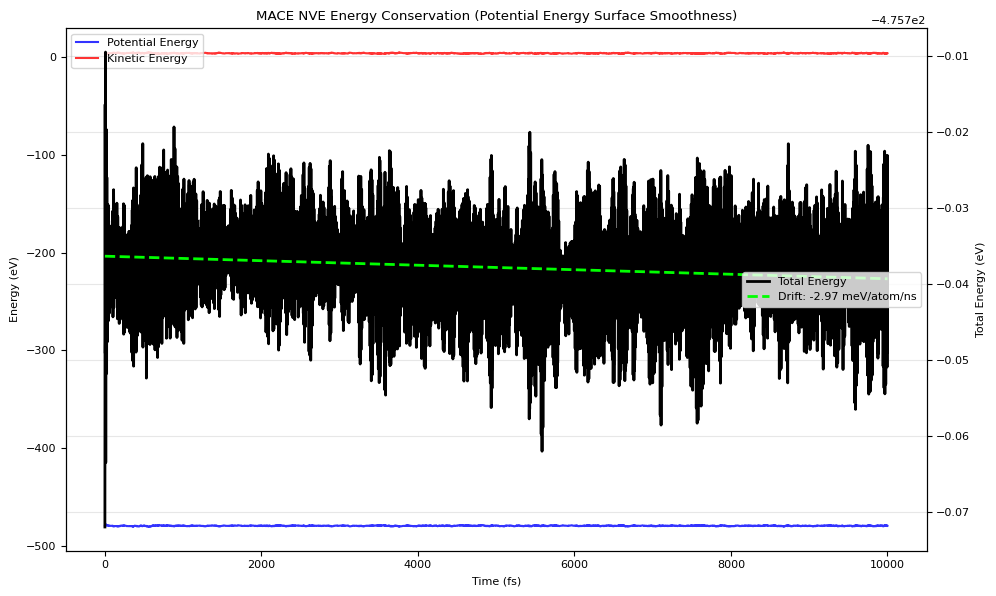

Analysis complete! Plot saved to /content/mace_nve_conservation.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from ase import units
from ase.md.verlet import VelocityVerlet
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution, Stationary, ZeroRotation
from mace.calculators import MACECalculator
from google.colab import drive

drive.mount('/content/drive')

base_dir = '/content/drive/MyDrive/MDProject'
init_structure_path = os.path.join(base_dir, 'valid.extxyz')
model_path = os.path.join(base_dir, 'new_simulation/1.NVT_300/A.1_10K/checkpoints/seed3/model_3000_pts_seed3_run-1_stagetwo.model')

print("Loading initial structure...")
# We take the first frame of the validation set as our starting point
atoms = read(init_structure_path, index=0)
num_atoms = len(atoms)

# Attach MACE Calculator
mac_calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')
atoms.calc = mac_calc

# Initialize Thermal Velocities (300K)
MaxwellBoltzmannDistribution(atoms, temperature_K=300.0)
Stationary(atoms)   # Remove center-of-mass translation (prevents drifting box)
ZeroRotation(atoms) # Remove center-of-mass rotation (prevents flying ice-cube effect)

# Set up the NVE Integrator (Velocity Verlet)
# We use a 1.0 fs timestep. NVE requires a purely Newtonian integrator without a thermostat.
timestep_fs = 1.0
dyn = VelocityVerlet(atoms, timestep_fs * units.fs)

# Arrays to store thermodynamics data
time_fs = []
epot_list = []
ekin_list = []
etot_list = []

# Observer function to record energies at each step
def log_thermo():
    epot = atoms.get_potential_energy()
    ekin = atoms.get_kinetic_energy()
    etot = epot + ekin

    current_time = dyn.get_time() / units.fs

    time_fs.append(current_time)
    epot_list.append(epot)
    ekin_list.append(ekin)
    etot_list.append(etot)

    step = dyn.get_number_of_steps()
    if step % 500 == 0:
        print(f"Step {step:>5} | Time {current_time:>6.1f} fs | E_pot: {epot:.3f} eV | E_kin: {ekin:.3f} eV | E_tot: {etot:.5f} eV")

# Attach the observer to log every step
dyn.attach(log_thermo, interval=1)

# Run the NVE Simulation
total_steps = 10000
print(f"\nRunning NVE simulation for {total_steps} steps ({total_steps * timestep_fs / 1000:.1f} ps)...")
dyn.run(total_steps)

# Calculate the Energy Drift Metric
# Convert time to nanoseconds (ns) and Energy to meV/atom for standardized reporting
time_ns = np.array(time_fs) / 1e6
etot_mev_per_atom = (np.array(etot_list) / num_atoms) * 1000

# Perform a linear regression on the Total Energy vs Time
slope, intercept = np.polyfit(time_ns, etot_mev_per_atom, 1)

print(f"Total Energy Drift: {slope:.3f} meV/atom/ns")
if abs(slope) < 2.0:
    print("Verdict: EXCELLENT. The MACE Potential Energy Surface is mathematically smooth.")
elif abs(slope) < 10.0:
    print("Verdict: ACCEPTABLE. The model is stable enough for standard NVT/NPT simulations.")
else:
    print("Verdict: POOR. The model has sharp artifacts causing severe energy leakage.")

# Plot the Results
plt.figure(figsize=(10, 6))

# We plot Potential and Kinetic energy against the left Y-axis
ax1 = plt.gca()
ax1.plot(time_fs, epot_list, color='blue', label='Potential Energy', alpha=0.8)
ax1.plot(time_fs, ekin_list, color='red', label='Kinetic Energy', alpha=0.8)
ax1.set_xlabel('Time (fs)')
ax1.set_ylabel('Energy (eV)')
ax1.tick_params(axis='y')
ax1.legend(loc='upper left')

# We plot Total Energy on a secondary Y-axis so we can zoom in on the tiny fluctuations
ax2 = ax1.twinx()
ax2.plot(time_fs, etot_list, color='black', label='Total Energy', linewidth=2)
ax2.set_ylabel('Total Energy (eV)', color='black')
ax2.tick_params(axis='y', labelcolor='black')

# Add a trendline to the Total Energy
etot_trend = (intercept + slope * time_ns) * num_atoms / 1000
ax2.plot(time_fs, etot_trend, color='lime', linestyle='--', linewidth=2, label=f'Drift: {slope:.2f} meV/atom/ns')
ax2.legend(loc='center right')

plt.title('MACE NVE Energy Conservation (Potential Energy Surface Smoothness)')
plt.grid(True, alpha=0.3)
plt.tight_layout()

save_path = '/content/mace_nve_conservation.png'
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Analysis complete! Plot saved to {save_path}")

In [ ]:
! pip install pymbar
! pip install ase
! pip install mace-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.4/107.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 6.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.7/387.7 kB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.8/222.8 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.8/346.8 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 453.1/453.1 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 5.2 MB/s eta 0:00:00
  Created wheel for python-hostlist: filename=python_hostlist-2.3.0-py3-none-any.whl size=39523 sha256=9d501b0fe04001faa3fe01535f33121349918c0ef70e0c7c511749005309b82a
  Stored in directory: /root/.cache/pip/wheels/05/2e/7e/39f980a5a0755f9